# MANOLO Innovation Lab: image classification workshop

In this notebook you train a convolutional neural network (CNN) on an image dataset, look inside it with explainable AI (XAI), make it smaller and faster with compression, and finally hand it over to **MANOLO**, which runs the same kind of analysis as a reproducible workflow on remote compute nodes.

| Section | What happens |
|---|---|
| 1. Imports and configuration | Choose the dataset, the preprocessing and the training settings |
| 2. Data | Load the images, compute the normalisation statistics, look at samples |
| 3. Model | Build a ResNet-18 from scratch |
| 4. Training | Train it and keep the best epoch |
| 5. Results | Measure it on the test split |
| 6. Explainability (XAI) | See which image regions drive its decisions, with Grad-CAM |
| 7. Compression | Quantize and prune it, and measure what that costs |
| 8. MANOLO | Register the dataset and the model, and run a workflow on MANOLO |

**How to use it**

- Run the cells from top to bottom. Start Jupyter from the `innovation_lab` folder: the notebook imports `architecture.py` (the model) and `lab_utils.py` (helper functions) from there.
- Everything the notebook produces goes to `outputs/<RUN_NAME>/`: the weights (`model.pt`), a report (`report.json`) and the MANOLO files.
- `lab_utils.py` holds the routine code (data loading, training loop, plots). Open it whenever you want to see how a step works.

**Cells marked `TODO` are yours to complete.** Sections 1 to 5 only need the configuration in section 1. Sections 6 and 7 are where you experiment: each `TODO` comes with a hint, and the text above it links to the documentation. Section 8 is written together during the MANOLO presentation.

In [3]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    LAB_DIR = Path("/content/drive/MyDrive/lab4")
    if not Path("/content/data/augcxr-dataset/train").is_dir():
        shutil.unpack_archive(str(LAB_DIR / "augcxr-dataset.zip"), "/content/data")
    os.chdir(LAB_DIR)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "grad-cam"])

assert Path("architecture.py").is_file() and Path("lab_utils.py").is_file(), "Missing architecture.py or lab_utils.py"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Imports and configuration

In [4]:
import copy
import json
import os
import random
import time
import warnings
from pathlib import Path

import lab_utils as lu
import matplotlib.pyplot as plt
import pandas as pd
import requests
import torch
import yaml
from architecture import build_model
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torch.ao import quantization as tq
from torch.nn.utils import prune

### Configuration

**Dataset.** `DATASET_DIR` must contain one folder per split and, inside each, one folder per class:

```
DATASET_DIR/
├── train/
│   ├── class_a/      image files (.jpg, .png, ...)
│   └── class_b/
├── val/
│   └── ...
└── test/
    └── ...
```

The class names are the folder names, and the labels follow their alphabetical order.

**Preprocessing.**

- `IMAGE_SIZE`: every image is resized to `IMAGE_SIZE` × `IMAGE_SIZE` pixels. Larger images keep more detail but train more slowly.
- `GRAYSCALE`: `True` converts the images to a single channel. That helps when colour carries no information (X-rays, CT scans): there is less input to learn from and the tensors are 3 times smaller. It can hurt when colour is a cue (vegetation, lesions on a leaf). Try both and compare.
- `AUGMENT`: random horizontal flips of the training images, a cheap way to make the model robust to mirrored inputs. Keep it off if left and right matter in your images.

**Training.** `EPOCHS` passes over the training set, `BATCH_SIZE` images per step, `LEARNING_RATE` and `WEIGHT_DECAY` for the optimiser. `NUM_WORKERS` processes load the images in parallel; set it to 0 if data loading fails on your machine.

**Outputs.** `RUN_NAME` names the output folder and, in section 8, your assets on MANOLO: use lowercase letters, digits and `-`. Set `TRAIN = False` to skip the training and reload the model saved in `outputs/<RUN_NAME>/`, e.g. after restarting the kernel.

In [5]:
# --- Dataset (TODO) --------------------------------------------------------------------------
DATASET_DIR = Path("/content/data/augcxr-dataset") if IN_COLAB else Path("augcxr-dataset")  # TODO: the folder that contains train/, val/ and test/
RUN_NAME = "826685-875455-xray"  # TODO: e.g. "team-a-wildfire": lowercase letters, digits, "-"

# --- Preprocessing ---------------------------------------------------------------------------
IMAGE_SIZE = 128  # TODO (optional): smaller is faster, larger keeps more detail
GRAYSCALE = True  # TODO: does colour matter for your dataset? Try True and False
AUGMENT = False  # TODO (optional): True adds random horizontal flips of the training images

# --- Training --------------------------------------------------------------------------------
TRAIN = True  # False: skip training and reload the model saved in OUTPUT_DIR
EPOCHS = 10
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2 if IN_COLAB else 0  # parallel image-loading processes; 0 if data loading fails
SEED = 42

OUTPUT_DIR = Path("outputs") / RUN_NAME
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

USE_AMP = DEVICE.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8  # bfloat16 mixed precision on the GPU: faster, less memory
random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

for split in ("train", "val", "test"):
    assert (DATASET_DIR / split).is_dir(), f"Folder not found: {DATASET_DIR / split}. Check DATASET_DIR."
print("torch", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name())
print("outputs:", OUTPUT_DIR.resolve())

torch 2.11.0+cu130 | device: cuda
GPU: Tesla T4
outputs: /content/drive/MyDrive/lab4/outputs/826685-875455-xray


## 2. Data

[`ImageFolder`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html) reads the images from the folder structure and assigns the labels. Each image then goes through a preprocessing pipeline built with [torchvision transforms v2](https://docs.pytorch.org/vision/stable/transforms.html):

1. decode the file into a tensor, and reduce it to 1 channel if `GRAYSCALE`;
2. resize it to `IMAGE_SIZE` × `IMAGE_SIZE`;
3. flip it horizontally at random (training images only, if `AUGMENT`);
4. scale the pixel values to [0, 1];
5. normalise each channel: subtract its mean and divide by its standard deviation.

**Why normalise, and with which statistics?**

Networks train faster and more stably when their inputs are centred around 0 with a similar spread. Models pretrained on ImageNet expect the ImageNet statistics, but this model is trained from scratch, so we use the mean and standard deviation of *our* training images. Only the training split is used, so that the validation and test images stay unseen. The same values are reused wherever the model sees images afterwards: evaluation, explainability, compression and the MANOLO dataset.

In [6]:
MEAN, STD = lu.compute_mean_std(DATASET_DIR / "train", IMAGE_SIZE, GRAYSCALE, seed=SEED)
print("per-channel mean:", MEAN, "| std:", STD)

per-channel mean: [0.5068] | std: [0.2606]


classes: ['NORMAL', 'PNEUMONIA']
train   7200 images | NORMAL: 3600, PNEUMONIA: 3600
val     1800 images | NORMAL: 900, PNEUMONIA: 900
test    1000 images | NORMAL: 500, PNEUMONIA: 500


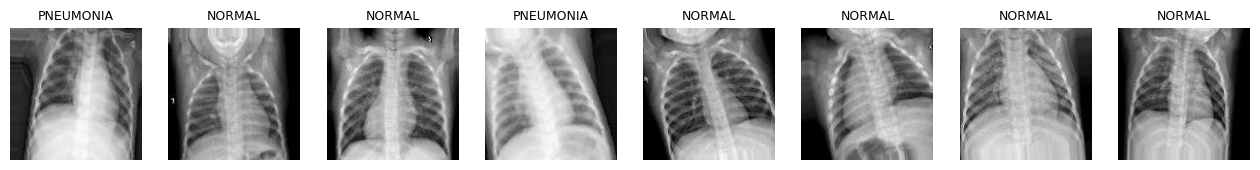

In [7]:
dsets = lu.make_datasets(DATASET_DIR, IMAGE_SIZE, MEAN, STD, GRAYSCALE, augment=AUGMENT)
loaders = lu.make_loaders(dsets, BATCH_SIZE, NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
CLASSES = dsets["train"].classes
print("classes:", CLASSES)
lu.describe(dsets)
lu.show_samples(dsets["val"], MEAN, STD, seed=SEED)

Check the class balance above. With very unequal classes, accuracy alone is misleading: a model that always predicts the largest class already looks good. The per-class recall in section 5 reveals it.

## 3. Model

[ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html) ([He et al., 2016](https://arxiv.org/abs/1512.03385)) is a classic CNN: a first 7×7 convolution (`conv1`), four stages (`layer1` to `layer4`) of residual blocks whose skip connections let gradients flow through deep networks, global average pooling and a final linear layer (`fc`) with one output per class. It has about 11 million parameters.

The model is defined in `architecture.py` and starts from random weights: no pretraining. `build_model(num_classes, in_channels)` adapts the first convolution to 1 channel when `GRAYSCALE` is on, and the last layer to the number of classes.

`architecture.py` follows MANOLO's contract: a `build_model(**model_kwargs)` function, and weights saved as a `state_dict` that loads into it. In section 8 you upload exactly this file, the weights and `MODEL_KWARGS`.

In [8]:
MODEL_KWARGS = {"num_classes": len(CLASSES), "in_channels": 1 if GRAYSCALE else 3}
model = build_model(**MODEL_KWARGS).to(DEVICE)
print(f"ResNet-18 {MODEL_KWARGS}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")
print("first layer:", model.conv1)
print("last layer: ", model.fc)

ResNet-18 {'num_classes': 2, 'in_channels': 1}: 11.2 M parameters
first layer: Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
last layer:  Linear(in_features=512, out_features=2, bias=True)


## 4. Training

`lu.fit` trains the model and returns its learning curves:

- **Loss**: cross-entropy between the predicted class probabilities and the true labels.
- **Optimiser**: [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html), with a [cosine schedule](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html) that lowers the learning rate smoothly to zero over the `EPOCHS`.
- **Mixed precision** on the GPU ([`torch.autocast`](https://docs.pytorch.org/docs/stable/amp.html) with bfloat16): faster and lighter, with no visible effect on accuracy.
- **Model selection**: after every epoch the model is evaluated on the validation split, and the weights of the best epoch are kept. The test split stays untouched until section 5.

The weights are saved as `outputs/<RUN_NAME>/model.pt`; the settings, the normalisation and the learning curves as `report.json`. Section 7 reuses the same `lu.fit` to fine-tune pruned models.

In [9]:
if TRAIN:
    history, best_epoch = lu.fit(
        model, loaders, EPOCHS, LEARNING_RATE, DEVICE, weight_decay=WEIGHT_DECAY, use_amp=USE_AMP
    )
    report = {
        "run_name": RUN_NAME,
        "dataset_dir": str(DATASET_DIR),
        "classes": CLASSES,
        "model_kwargs": MODEL_KWARGS,
        "preprocessing": {"image_size": IMAGE_SIZE, "grayscale": GRAYSCALE, "augment": AUGMENT, "mean": MEAN, "std": STD},
        "hyperparameters": {
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "seed": SEED,
        },
        "best_epoch": best_epoch,
        "history": history,
    }
    lu.save_model(model, report, OUTPUT_DIR)
else:
    model, report = lu.load_model(OUTPUT_DIR, DEVICE)
    history, best_epoch = report["history"], report["best_epoch"]
    assert report["model_kwargs"] == MODEL_KWARGS and report["preprocessing"]["mean"] == MEAN, (
        "The saved model was trained with other settings: restore them, or set TRAIN = True"
    )
print("model and report in", OUTPUT_DIR)

epoch  1/10 | train loss 0.2117 acc 0.9176 | val loss 0.2954 acc 0.9100 | 18s
epoch  2/10 | train loss 0.1054 acc 0.9600 | val loss 0.2173 acc 0.9144 | 9s
epoch  3/10 | train loss 0.0666 acc 0.9751 | val loss 0.2844 acc 0.8994 | 9s
epoch  4/10 | train loss 0.0469 acc 0.9824 | val loss 0.2694 acc 0.9317 | 9s
epoch  5/10 | train loss 0.0220 acc 0.9925 | val loss 0.2847 acc 0.9278 | 9s
epoch  6/10 | train loss 0.0138 acc 0.9957 | val loss 0.2704 acc 0.9400 | 10s
epoch  7/10 | train loss 0.0039 acc 0.9990 | val loss 0.1953 acc 0.9506 | 9s
epoch  8/10 | train loss 0.0009 acc 1.0000 | val loss 0.2070 acc 0.9506 | 9s
epoch  9/10 | train loss 0.0009 acc 1.0000 | val loss 0.2014 acc 0.9494 | 9s
epoch 10/10 | train loss 0.0007 acc 1.0000 | val loss 0.2025 acc 0.9494 | 9s
best epoch 7 (val acc 0.9506)
model and report in outputs/826685-875455-xray


## 5. Results

The test split is used here for the first time, so it gives an honest estimate of how the model behaves on new images.

- **Accuracy**: the fraction of test images classified correctly.
- **Recall per class**: for each class, the fraction of its images the model finds. It reveals a model that neglects a class, which accuracy can hide.
- **Confusion matrix**: rows are the true classes, columns the predictions; everything off the diagonal is an error.
- **Learning curves**: a training loss that keeps falling while the validation loss rises means the model is overfitting, i.e. memorising the training images.

test accuracy 0.9780 | loss 0.0829
recall per class: {'NORMAL': 0.976, 'PNEUMONIA': 0.98}


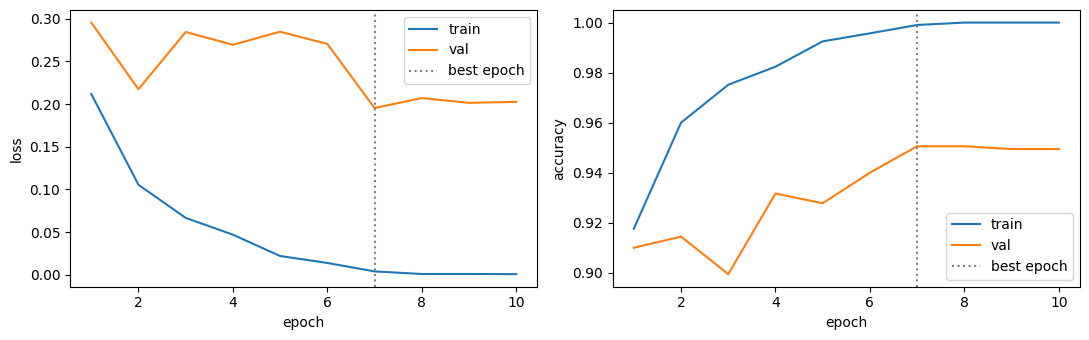

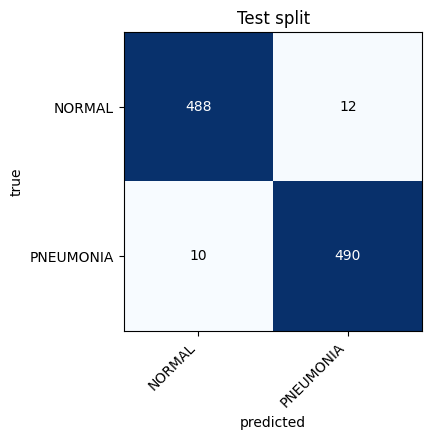

In [10]:
test_metrics = lu.evaluate(model, loaders["test"], DEVICE, USE_AMP)
report["test"] = test_metrics
lu.save_report(report, OUTPUT_DIR)
print(f"test accuracy {test_metrics['accuracy']:.4f} | loss {test_metrics['loss']:.4f}")
print("recall per class:", dict(zip(CLASSES, test_metrics["per_class_recall"])))
lu.plot_history(history, best_epoch)
lu.plot_confusion(test_metrics["confusion"], CLASSES, "Test split")

### Check the saved model as MANOLO will load it

MANOLO rebuilds the model with `build_model(**model_kwargs)` and loads `model.pt` into it strictly: every weight must match. `lu.load_model` does the same, so the accuracy below must equal the one above, up to tiny GPU rounding differences.

In [11]:
reloaded, _ = lu.load_model(OUTPUT_DIR, DEVICE)
print(f"reloaded test accuracy {lu.evaluate(reloaded, loaders['test'], DEVICE, USE_AMP)['accuracy']:.4f}")
del reloaded

reloaded test accuracy 0.9780


### Task 1 answers

**1.1** We used AugCXR to classify NORMAL and PNEUMONIA images. Grayscale preserves the information needed in these X-rays while reducing the input to one channel. Images were resized to 128 x 128 pixels, and horizontal-flip augmentation was disabled.

**1.2** Both classes have 3,600 training images, 900 validation images and 500 test images. The splits are balanced, so an always-one-class classifier would obtain 50% accuracy. Accuracy can still hide different error rates between classes, which is why we also report their recalls and the confusion matrix.

**1.3** Test accuracy was **97.8%** and test loss was **0.0829**. Recall was **97.6% for NORMAL** and **98.0% for PNEUMONIA**. With true labels in rows and predicted labels in columns, the confusion matrix was:

| True / predicted | NORMAL | PNEUMONIA |
|---|---:|---:|
| NORMAL | 488 | 12 |
| PNEUMONIA | 10 | 490 |

There were 22 errors in 1,000 test images, with similar recall for both classes. Reloading the saved model reproduced the 97.8% test accuracy.

The selected checkpoint was epoch 7, with 99.90% training accuracy and 95.06% validation accuracy. Training accuracy subsequently reached 100%, while validation accuracy stayed near 95% and validation loss stopped improving. This indicates some overfitting rather than underfitting; the later epochs fitted the training data more closely without improving validation performance.

## 6. Explainability (XAI)

A test accuracy says *how often* the model is right, not *why*. A model can score well for the wrong reasons, for example by relying on a watermark, the image border or a background that happens to correlate with the class (the "Clever Hans" effect). Explainable AI (XAI) methods make the decision process visible, so that we can trust, debug or challenge the model. The [Interpretable Machine Learning](https://christophm.github.io/interpretable-ml-book/) book is a good general introduction.

### Grad-CAM

[Grad-CAM](https://arxiv.org/abs/1610.02391) (Selvaraju et al., 2017) produces a heatmap of the image regions that support a given class:

1. Pick a convolutional layer, the **target layer**. Its output is a stack of feature maps $A^k$; for `layer4` of a ResNet-18 on 256×256 inputs, 512 maps of 8×8.
2. Back-propagate the score $y^c$ of class $c$ to that layer and average the gradient of each map over its positions: $\alpha_k^c = \frac{1}{Z}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$. This weight says how much map $k$ matters for class $c$.
3. Combine the maps with these weights and keep the positive evidence only: $L^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right)$.
4. Upsample $L^c$ to the image size and overlay it on the image: red regions pushed the model towards class $c$.

Grad-CAM needs no retraining and works with any CNN. Its limits: the heatmap is as coarse as the target layer, and it shows *where* the model looks, not *what* it sees there.

We use the [pytorch-grad-cam](https://github.com/jacobgil/pytorch-grad-cam) library ([tutorials and method comparison](https://jacobgil.github.io/pytorch-gradcam-book/introduction.html)). The pattern is always the same:

```python
with GradCAM(model=model, target_layers=[layer]) as cam:
    heatmaps = cam(input_tensor=images, targets=targets)  # one heatmap per image, values in [0, 1]
```

`targets=None` explains the predicted class; `[ClassifierOutputTarget(c)] * n` explains class `c` for each of the `n` images.

### 6.1 Grad-CAM on test images

Four random test images per class, explained for the class the model predicted. Top row: the image as the model sees it. Bottom row: the Grad-CAM overlay, with the prediction and its probability, in green if correct and red if wrong.

In [12]:
test_set = dsets["test"]
indices = lu.sample_per_class(test_set, per_class=4, seed=SEED)
images = torch.stack([test_set[index][0] for index in indices]).to(DEVICE)
labels = [test_set.targets[index] for index in indices]
model.eval()
with torch.no_grad():
    probabilities = model(images).softmax(dim=1).cpu()

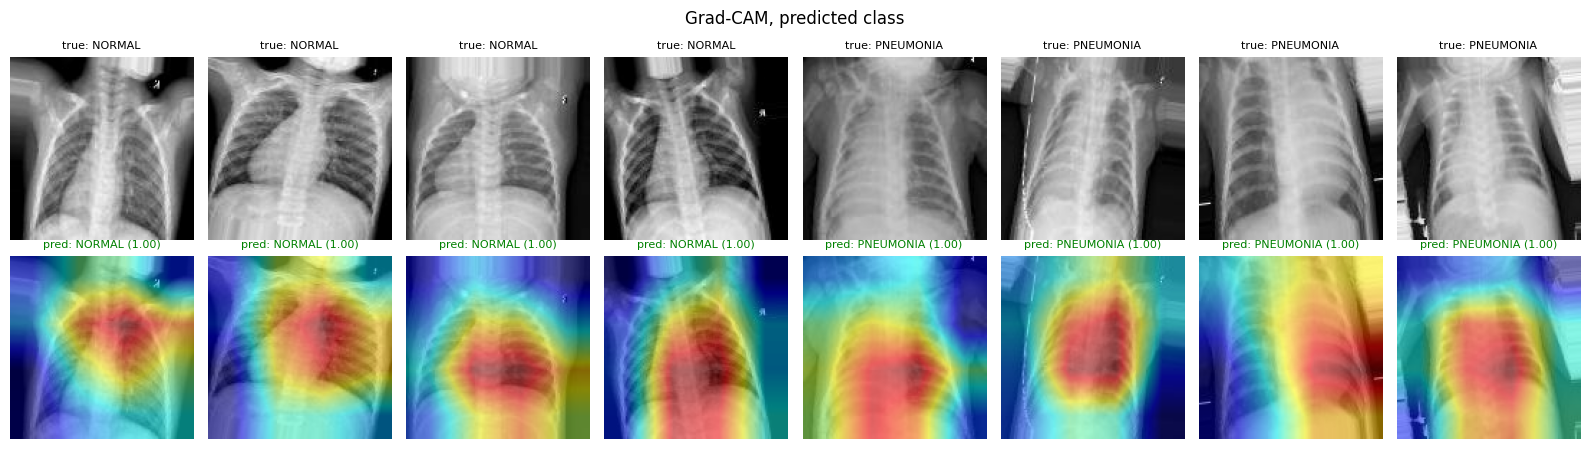

In [13]:
# TODO 1: choose the layer to explain. Grad-CAM needs a convolutional layer, usually the last one.
#   Hint: print(model) lists the layers; the last residual block is model.layer4[-1].
target_layers = [model.layer4[-1]]

# TODO 2: create a GradCAM object and compute one heatmap per image for the predicted class.
#   Hint: follow the pattern in the markdown above; targets=None explains the predicted class.
with GradCAM(model=model, target_layers=target_layers) as cam:
    heatmaps = cam(input_tensor=images, targets=None)

lu.plot_explanations(images, heatmaps, labels, probabilities, CLASSES, MEAN, STD, "Grad-CAM, predicted class")

### 6.2 Evidence for each class

Grad-CAM can explain any class, not only the predicted one. Comparing the heatmaps of every class on the same images shows which regions argue for and against each decision. The target is `ClassifierOutputTarget(class_index)`.

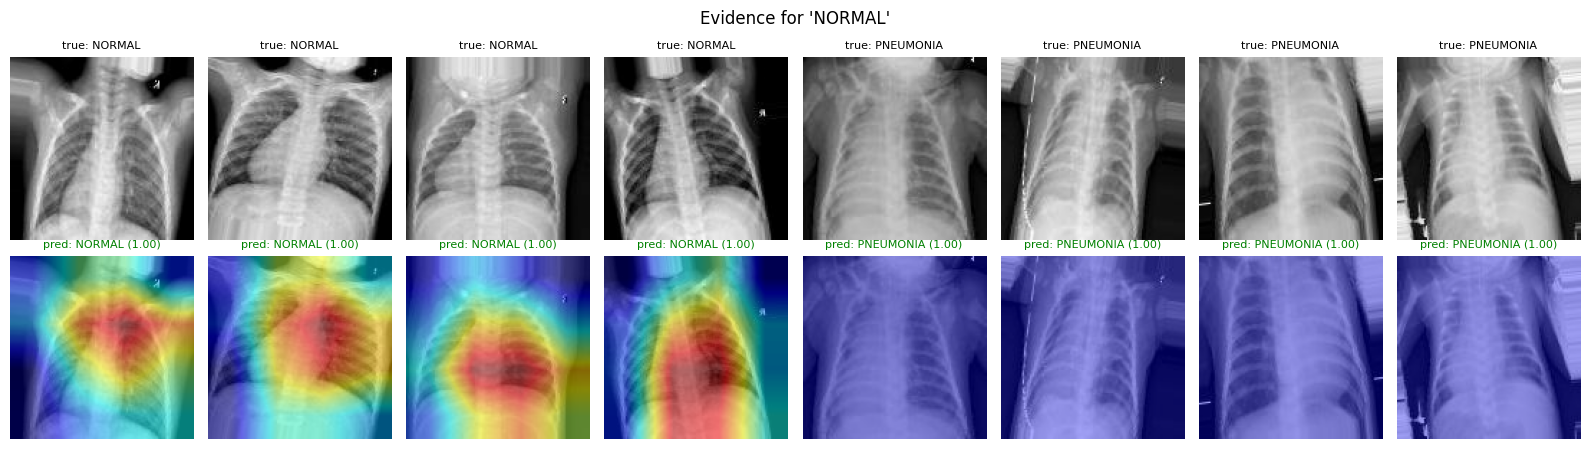

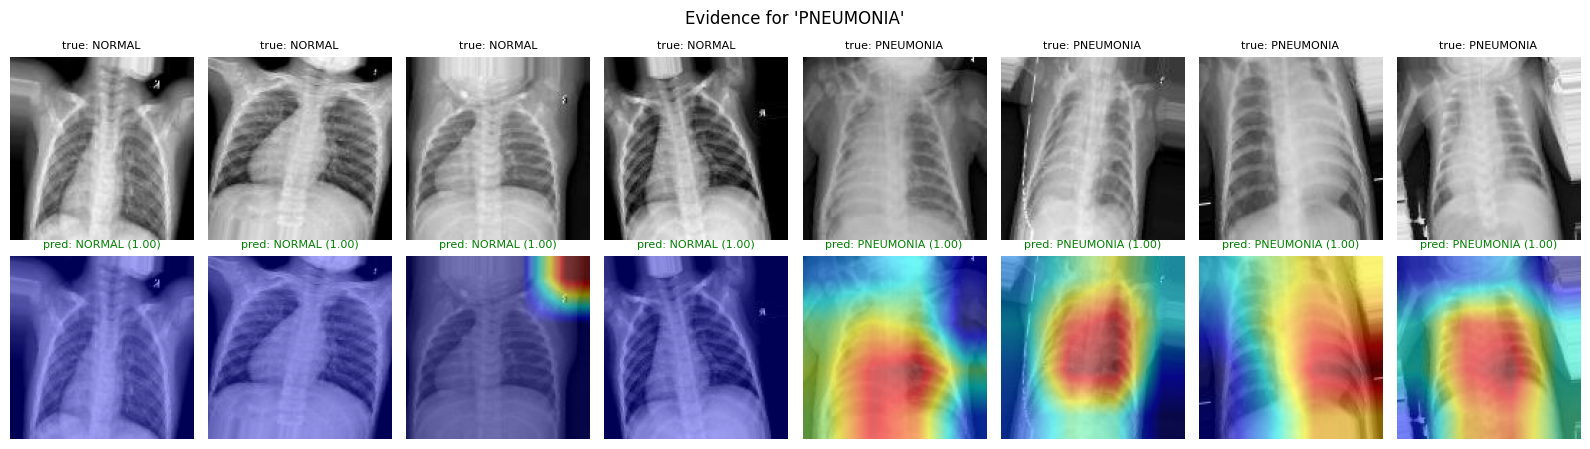

In [14]:
for class_index, class_name in enumerate(CLASSES):

    # TODO 3: one target per image, asking Grad-CAM to explain class `class_index`.
    #   Hint: ClassifierOutputTarget(class_index), repeated len(images) times.
    targets = [ClassifierOutputTarget(class_index) for _ in range(len(images))]
    with GradCAM(model=model, target_layers=[model.layer4[-1]]) as cam:
        heatmaps = cam(input_tensor=images, targets=targets)
    lu.plot_explanations(images, heatmaps, labels, probabilities, CLASSES, MEAN, STD, f"Evidence for '{class_name}'")

### 6.3 Which layer to explain?

Early layers have a high resolution but respond to simple patterns (edges, textures); late layers have a low resolution but encode the concepts the classifier uses. For 256×256 inputs, the output of `layer2` is 32×32, `layer3` 16×16 and `layer4` 8×8. Compare the heatmaps of the same images at each depth.

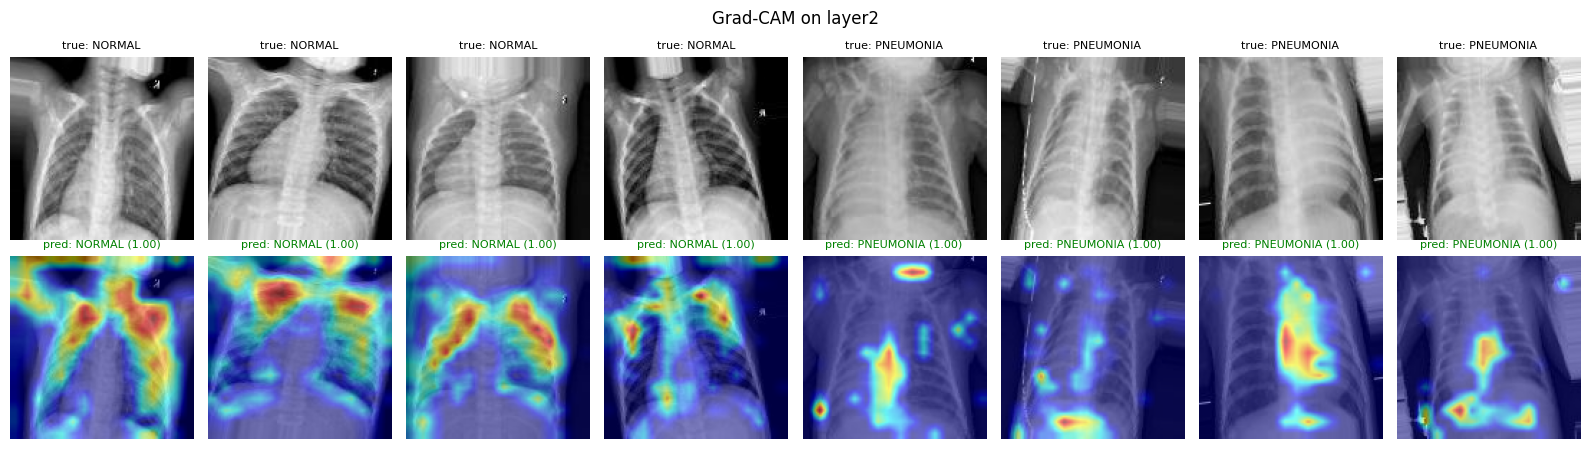

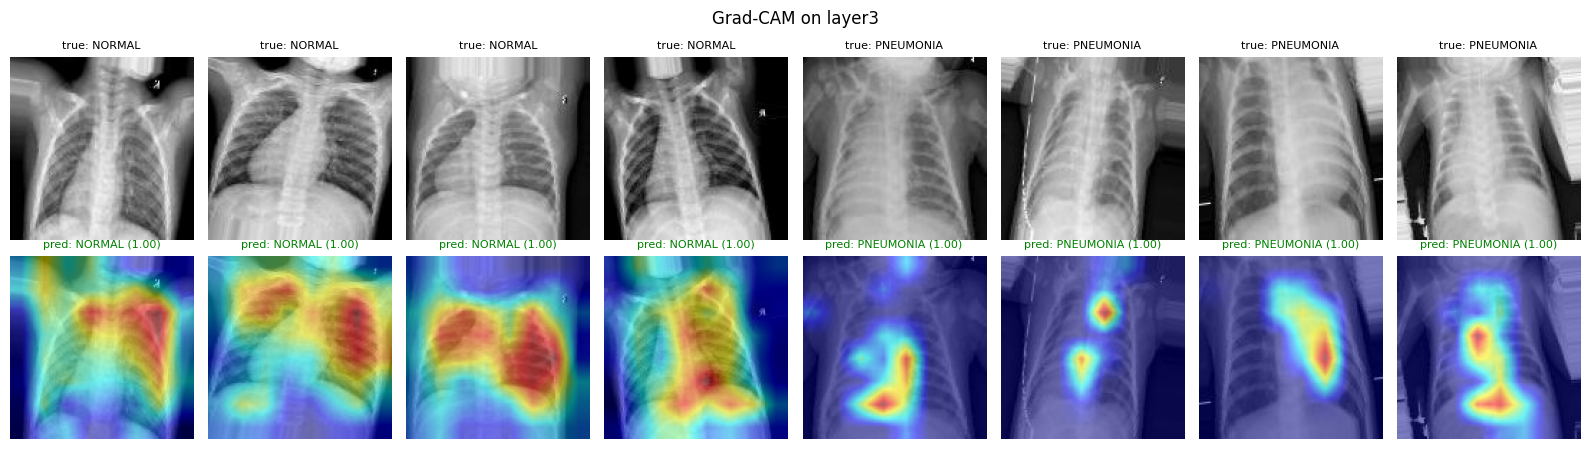

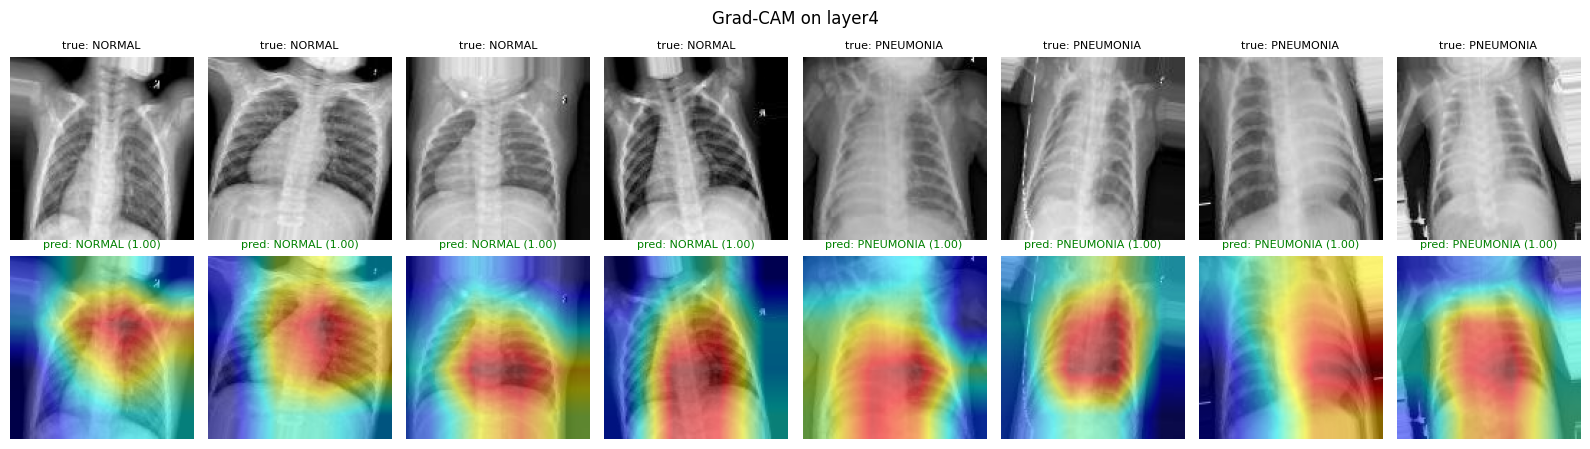

In [15]:
# TODO 4: map a name to each layer you want to compare, e.g. {"layer2": model.layer2[-1], ...}
layers_to_compare = {
    "layer2": model.layer2[-1],
    "layer3": model.layer3[-1],
    "layer4": model.layer4[-1],
}

for name, layer in layers_to_compare.items():
    with GradCAM(model=model, target_layers=[layer]) as cam:
        heatmaps = cam(input_tensor=images, targets=None)
    lu.plot_explanations(images, heatmaps, labels, probabilities, CLASSES, MEAN, STD, f"Grad-CAM on {name}")

### 6.4 Explaining the mistakes

The most informative explanations are often those of the errors. This finds the misclassified test images and explains up to eight of them: is the image genuinely ambiguous, or is the model looking at the wrong place?

22 of 1000 test images are misclassified


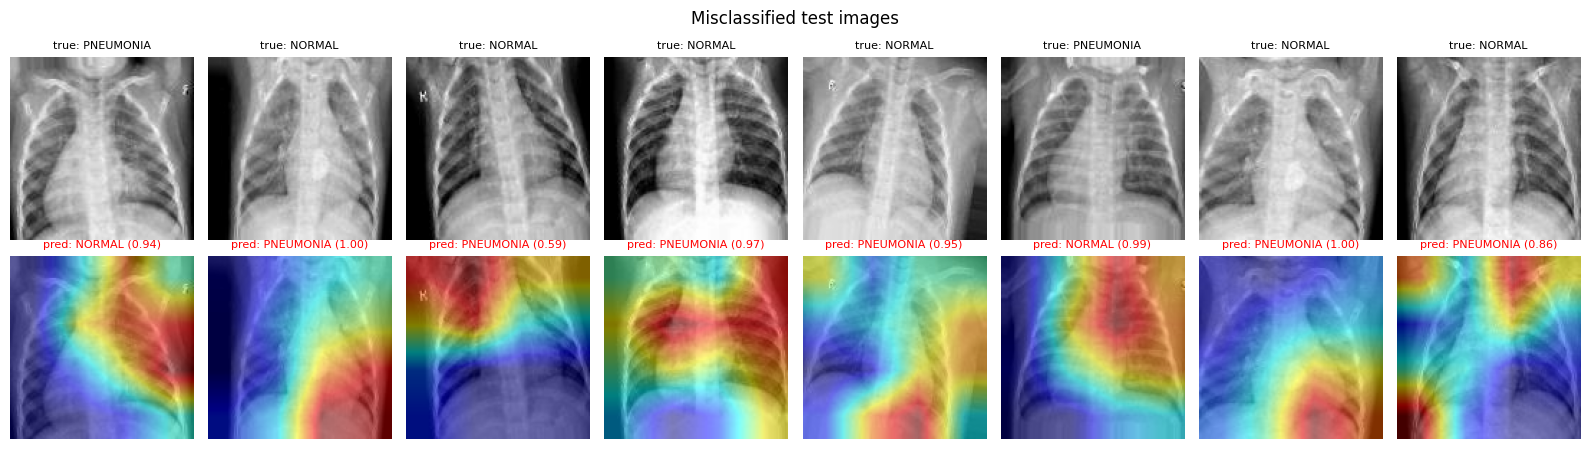

In [16]:
logits, test_labels = lu.predict(model, loaders["test"], DEVICE, USE_AMP)  # in dataset order

# TODO 5: the list of indices of the misclassified test images.
#   Hint: compare logits.argmax(dim=1) with test_labels, then .nonzero().flatten().tolist()
wrong = (logits.argmax(dim=1) != test_labels).nonzero(as_tuple=True)[0].tolist()
print(f"{len(wrong)} of {len(test_labels)} test images are misclassified")

if wrong:
    picked = random.Random(SEED).sample(wrong, min(8, len(wrong)))
    error_images = torch.stack([test_set[index][0] for index in picked]).to(DEVICE)
    error_labels = [test_set.targets[index] for index in picked]
    with GradCAM(model=model, target_layers=[model.layer4[-1]]) as cam:
        heatmaps = cam(input_tensor=error_images, targets=None)
    lu.plot_explanations(
        error_images, heatmaps, error_labels, logits[picked].softmax(dim=1), CLASSES, MEAN, STD, "Misclassified test images"
    )

### 6.5 Questions and ideas

- Does the model look at the object of interest, or at the background, the borders or text?
- Do the heatmaps change between `GRAYSCALE = True` and `False`?
- Try another method from pytorch-grad-cam by replacing `GradCAM`: `GradCAMPlusPlus`, `HiResCAM`, `ScoreCAM` (gradient-free, slower) or `EigenCAM` (class-agnostic). The [method comparison](https://jacobgil.github.io/pytorch-gradcam-book/introduction.html) explains their differences.
- MANOLO runs Grad-CAM as well (the `explainability` block of `workflow.yaml`, section 8). Compare its report with your heatmaps.

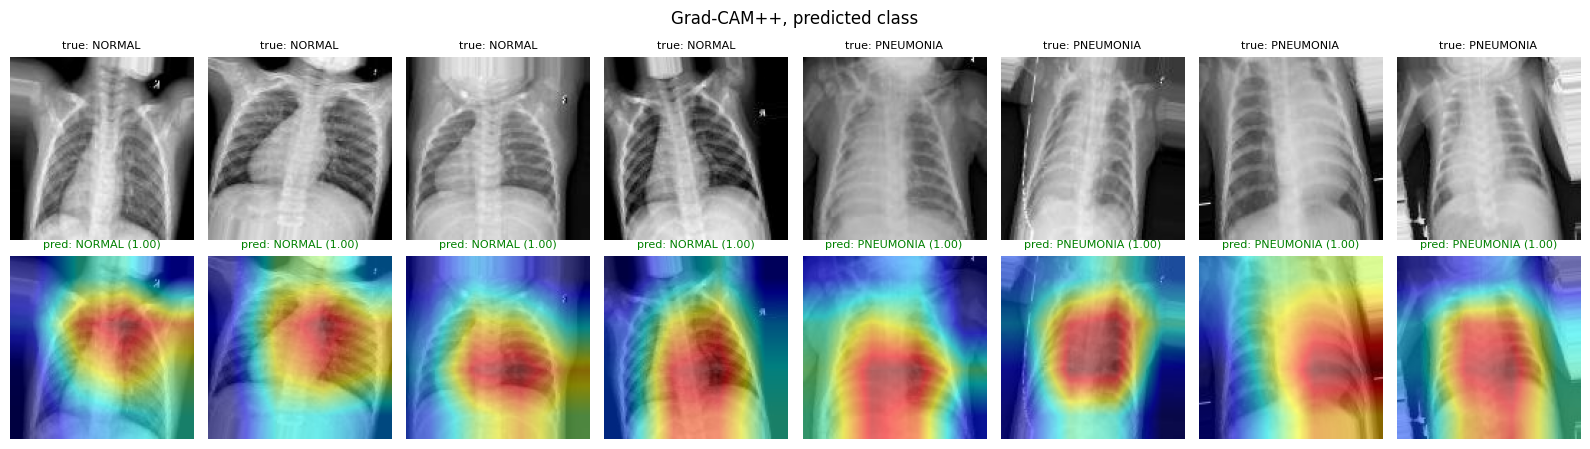

In [17]:
with GradCAMPlusPlus(model=model, target_layers=[model.layer4[-1]]) as cam:
    plus_heatmaps = cam(input_tensor=images, targets=None)
lu.plot_explanations(
    images, plus_heatmaps, labels, probabilities, CLASSES, MEAN, STD, "Grad-CAM++, predicted class"
)

### Task 2 answers

**2.1** In the eight correctly classified examples, predicted-class Grad-CAM mostly highlights broad regions inside the chest. It does not precisely isolate the lungs, and some heatmaps extend towards the chest boundary. In the class-specific comparison, asking for PNEUMONIA evidence in the third NORMAL image highlights the upper-right image corner rather than the lung region. This suggests that some class evidence can come from irrelevant features, even when the final prediction is correct.

**2.2** For our 128 x 128 inputs, layer2, layer3 and layer4 have spatial resolutions of 16 x 16, 8 x 8 and 4 x 4. The layer2 maps contain small, scattered hotspots along chest contours and local features. Layer3 combines these into larger regions, while layer4 produces broad, smooth regions over the chest. Deeper layers provide evidence from features closer to the final decision, but lose spatial detail; the large layer4 hotspots cannot identify a precise abnormality.

**2.3** The model misclassified 22 test images. In the eight displayed errors, several heatmaps concentrate near image boundaries: the second and seventh examples highlight the lower-right area, while the third highlights the upper-left region near a letter marker. These patterns suggest possible reliance on irrelevant cues. Other errors still highlight the chest, so attention to the wrong region does not explain every mistake. The third example has a predicted probability of 0.59, whereas several wrong predictions have probabilities above 0.94, showing that confidence does not ensure correctness. The images and heatmaps alone do not establish whether an error is due to ambiguity or a learned shortcut.

**2.4** Grad-CAM++ and Grad-CAM give very similar explanations on the same eight images, layer and predicted classes. Their main hotspots occupy the same chest regions, with small changes in extent and intensity. This supports agreement between these two methods on this sample, but does not prove that the highlighted regions are the correct diagnostic evidence.

## 7. Compression

A trained model has to fit and run where it is deployed, often a small device (edge hardware, a phone, a drone) with little memory, compute and energy. Compression makes the model smaller and faster, ideally at a small cost in accuracy. Two standard post-training families:

- **Quantization** (7.1) stores the numbers with fewer bits.
- **Pruning** (7.2) removes the least useful weights.

Each variant is measured on the test split with: **accuracy**; **size** of the saved `state_dict` (the `.pt` file); **sparsity**, the fraction of weights that are exactly zero; and **CPU latency**, the time of one forward pass over a fixed batch of 32 images on the CPU, where small devices run. The rows collect in `results` and are compared in 7.3.

In [18]:
latency_count = min(32, len(dsets["test"]))
example_batch = torch.stack([dsets["test"][index][0] for index in range(latency_count)])  # fixed batch for the latency
results = [
    {
        "variant": "baseline (float32)",
        "accuracy": test_metrics["accuracy"],
        "size (MB)": lu.state_dict_size_mb(model),
        "sparsity": lu.weight_sparsity(model),
        "CPU latency (ms)": lu.cpu_latency_ms(model, example_batch),
    }
]
pd.DataFrame(results)

,variant,accuracy,size (MB),sparsity,CPU latency (ms)
0,baseline (float32),0.978,44.763787,0.0,575.376663


### 7.1 Quantization

**What it is.** The weights and activations of the model are 32-bit floating-point numbers. Quantization maps them to 8-bit integers with an affine transform, $x \approx s\,(q - z)$, where $q$ is the integer, $s$ a scale and $z$ a zero point, chosen from the range of the values. The weights become 4 times smaller, and integer arithmetic is faster and more energy-efficient on CPUs and dedicated hardware. The price is a small rounding error ([Jacob et al., 2018](https://arxiv.org/abs/1712.05877)).

**How it is done here: post-training static quantization** ([PyTorch quantization documentation](https://docs.pytorch.org/docs/stable/quantization.html), [eager-mode tutorial](https://docs.pytorch.org/tutorials/advanced/static_quantization_tutorial.html)):

1. **Quantizable copy.** torchvision ships a [quantizable ResNet-18](https://docs.pytorch.org/vision/stable/models.html) with the same layers plus `QuantStub` / `DeQuantStub`, where the tensors enter and leave the integer domain. `lu.quantizable_copy` builds it on the CPU and loads our weights.
2. **Fuse** each convolution with its batch normalisation and ReLU (`model.fuse_model(is_qat=False)`): one operation instead of three, faster and more accurate once quantized.
3. **Configure** (`model.qconfig = tq.get_default_qconfig(engine)`): which *observers* record the value ranges, and which integer types to use.
4. **Prepare** (`tq.prepare(model, inplace=True)`): insert the observers.
5. **Calibrate**: run some training images through the model so that the observers see realistic activations (`lu.calibrate`).
6. **Convert** (`tq.convert(model, inplace=True)`): replace every layer with its int8 version, using the recorded ranges.

The other flavours are *dynamic* quantization (activations quantized on the fly, mostly for linear and recurrent layers) and *quantization-aware training* (the rounding is simulated during training: the most accurate).

**Notes.**

- Int8 kernels run on the **CPU only**, so the quantized model is evaluated on the CPU. It takes longer than the GPU evaluations above.
- The kernels depend on the platform: `x86` or `fbgemm` on Linux, `onednn` on Windows. `lu.quantization_engine()` picks the available one.
- `torch.ao.quantization` is deprecated in PyTorch 2.12 in favour of [torchao](https://github.com/pytorch/ao), but still works with the PyTorch version MANOLO uses; its deprecation warnings are silenced below.

In [19]:
QUANT_ENGINE = lu.quantization_engine()
torch.backends.quantized.engine = QUANT_ENGINE
print("int8 engine:", QUANT_ENGINE)

CALIBRATION_BATCHES = 10  # TODO (optional): how many batches are enough? Try 1, 10 and 50

calibration_set = lu.make_datasets(DATASET_DIR, IMAGE_SIZE, MEAN, STD, GRAYSCALE, augment=False)["train"]
calibration_loader = torch.utils.data.DataLoader(
    calibration_set, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
)

int8_model = lu.quantizable_copy(model)  # 1. quantizable float copy, on the CPU
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    # TODO 6:  fuse conv + batch norm + ReLU.          Hint: the quantizable ResNet has a fuse_model(is_qat=False) method
    int8_model.fuse_model(is_qat=False)
    # TODO 7:  set int8_model.qconfig.                 Hint: tq.get_default_qconfig(QUANT_ENGINE)
    int8_model.qconfig = tq.get_default_qconfig(QUANT_ENGINE)
    # TODO 8:  insert the observers.                   Hint: tq.prepare(..., inplace=True)
    tq.prepare(int8_model, inplace=True)
    # TODO 9:  calibrate on CALIBRATION_BATCHES training batches.   Hint: lu.calibrate
    lu.calibrate(int8_model, calibration_loader, CALIBRATION_BATCHES)
    # TODO 10: convert to int8.                        Hint: tq.convert(..., inplace=True)
    tq.convert(int8_model, inplace=True)

int8_metrics = lu.evaluate(int8_model, loaders["test"], torch.device("cpu"))
results.append(
    {
        "variant": "int8 quantized",
        "accuracy": int8_metrics["accuracy"],
        "size (MB)": lu.state_dict_size_mb(int8_model),
        "sparsity": float("nan"),
        "CPU latency (ms)": lu.cpu_latency_ms(int8_model, example_batch),
    }
)
pd.DataFrame(results)

int8 engine: x86


/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  super().__init__(


,variant,accuracy,size (MB),sparsity,CPU latency (ms)
0,baseline (float32),0.978,44.763787,0.0,575.376663
1,int8 quantized,0.977,11.302623,NaN,378.312490


### 7.2 Pruning

**What it is.** Many weights of a trained network are close to zero and contribute little. Pruning sets them to exactly zero. The classic criterion is the magnitude: the smallest weights in absolute value go first ([Han et al., 2015](https://arxiv.org/abs/1506.02626)). Accuracy drops as more weights are removed, and a short **fine-tuning** afterwards lets the remaining weights compensate. [Blalock et al., 2020](https://arxiv.org/abs/2003.03033) survey the field.

**The choices.**

- *Unstructured* (individual weights) or *structured* (whole channels or filters).
- *Layer-wise* (the same fraction in every layer) or *global* (one ranking over the whole network, so that the layers with the most redundant weights lose the most).

**How it is done here**, with [`torch.nn.utils.prune`](https://docs.pytorch.org/tutorials/intermediate/pruning_tutorial.html):

1. [`prune.global_unstructured`](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.prune.global_unstructured.html)`(parameters, pruning_method=prune.L1Unstructured, amount=a)` ranks all convolution and linear weights (`lu.prunable_weights(model)`) by magnitude and zeroes the fraction `a`. PyTorch does not delete them: each layer keeps its original weights in `weight_orig`, a 0/1 `weight_mask`, and computes `weight = weight_orig * weight_mask` before every forward pass.
2. Optionally, fine-tune for `FINETUNE_EPOCHS` with `lu.fit`, the training function of section 4. The mask stays active, so the pruned weights stay at zero.
3. `prune.remove(module, "weight")` makes the zeros permanent and drops the mask.

**Note.** Zeros are stored like any other number: unstructured pruning reduces **neither the file size nor the latency** on standard hardware, which would need sparse storage formats and kernels. Structured pruning, which removes whole channels and really shrinks the network, is available in [Torch-Pruning](https://github.com/VainF/Torch-Pruning), installed with MANOLO.

In [20]:
PRUNING_AMOUNTS = (0.3, 0.5, 0.7, 0.9)  # TODO (optional): which amounts are worth testing?
FINETUNE_EPOCHS = 2  # TODO (optional): 0 disables the fine-tuning
FINETUNE_LR = 1e-4  # smaller than LEARNING_RATE: small adjustments only

for amount in PRUNING_AMOUNTS:
    pruned = copy.deepcopy(model)

    # TODO 11: zero the `amount` smallest-magnitude conv/linear weights of `pruned`, ranked globally.
    #   Hint: prune.global_unstructured(lu.prunable_weights(pruned), pruning_method=..., amount=...)
    prune.global_unstructured(
        lu.prunable_weights(pruned), pruning_method=prune.L1Unstructured, amount=amount
    )
    before_metrics = lu.evaluate(pruned, loaders["test"], DEVICE, USE_AMP)

    dense = copy.deepcopy(model).cpu()
    dense_state = pruned.state_dict()
    for module_name, module in pruned.named_modules():
        if hasattr(module, "weight_mask"):
            prefix = f"{module_name}." if module_name else ""
            dense_state[prefix + "weight"] = dense_state.pop(prefix + "weight_orig") * dense_state.pop(prefix + "weight_mask")
    dense.load_state_dict(dense_state)
    results.append({
        "variant": f"pruned {amount:.0%}",
        "accuracy": before_metrics["accuracy"],
        "size (MB)": lu.state_dict_size_mb(dense),
        "sparsity": lu.weight_sparsity(dense),
        "CPU latency (ms)": lu.cpu_latency_ms(dense, example_batch),
    })
    del dense, dense_state

    if FINETUNE_EPOCHS:

        # TODO 12: fine-tune `pruned` for FINETUNE_EPOCHS epochs with FINETUNE_LR.   Hint: lu.fit, as in section 4
        lu.fit(
            pruned, loaders, FINETUNE_EPOCHS, FINETUNE_LR, DEVICE,
            weight_decay=WEIGHT_DECAY, use_amp=USE_AMP,
        )

    # TODO 13: make the pruning permanent on every pruned layer.   Hint: prune.remove(module, name)
    for module, name in lu.prunable_weights(pruned):
        prune.remove(module, name)

    if FINETUNE_EPOCHS:
        after_metrics = lu.evaluate(pruned, loaders["test"], DEVICE, USE_AMP)
        results.append({
            "variant": f"pruned {amount:.0%} + fine-tuned",
            "accuracy": after_metrics["accuracy"],
            "size (MB)": lu.state_dict_size_mb(pruned),
            "sparsity": lu.weight_sparsity(pruned),
            "CPU latency (ms)": lu.cpu_latency_ms(pruned, example_batch),
        })
    del pruned
pd.DataFrame(results)

epoch  1/2 | train loss 0.0040 acc 0.9989 | val loss 0.2275 acc 0.9517 | 10s
epoch  2/2 | train loss 0.0014 acc 0.9999 | val loss 0.2334 acc 0.9522 | 10s
best epoch 2 (val acc 0.9522)
epoch  1/2 | train loss 0.0060 acc 0.9986 | val loss 0.2335 acc 0.9450 | 10s
epoch  2/2 | train loss 0.0017 acc 0.9997 | val loss 0.2195 acc 0.9483 | 10s
best epoch 2 (val acc 0.9483)
epoch  1/2 | train loss 0.0252 acc 0.9906 | val loss 0.1842 acc 0.9511 | 10s
epoch  2/2 | train loss 0.0048 acc 0.9990 | val loss 0.1839 acc 0.9472 | 10s
best epoch 1 (val acc 0.9511)
epoch  1/2 | train loss 0.1895 acc 0.9451 | val loss 0.1775 acc 0.9389 | 9s
epoch  2/2 | train loss 0.0970 acc 0.9768 | val loss 0.1539 acc 0.9500 | 9s
best epoch 2 (val acc 0.9500)


,variant,accuracy,size (MB),sparsity,CPU latency (ms)
0,baseline (float32),0.978,44.763787,0.0,575.376663
1,int8 quantized,0.977,11.302623,NaN,378.312490
2,pruned 30%,0.965,44.762059,0.3,854.925084
3,pruned 30% + fine-tuned,0.974,44.763787,0.3,633.144363
4,pruned 50%,0.856,44.762059,0.5,584.757015
5,pruned 50% + fine-tuned,0.973,44.763787,0.5,675.472532
6,pruned 70%,0.500,44.762059,0.7,579.293159
7,pruned 70% + fine-tuned,0.973,44.763787,0.7,587.298566
8,pruned 90%,0.500,44.762059,0.9,584.395104
9,pruned 90% + fine-tuned,0.971,44.763787,0.9,579.703109


### 7.3 Comparison

All the variants side by side. *Accuracy change* is in percentage points relative to the baseline; *size reduction* and *speed-up* are factors (×) relative to the baseline. The plot shows the test accuracy against the sparsity of the pruned models, with and without fine-tuning, and the baseline and int8 accuracies as reference lines.

,variant,accuracy,size (MB),sparsity,CPU latency (ms),accuracy change (pp),size reduction (x),speed-up (x)
0,baseline (float32),0.978,44.764,0.0,575.377,0.0,1.00,1.000
1,int8 quantized,0.977,11.303,NaN,378.312,-0.1,3.96,1.521
2,pruned 30%,0.965,44.762,0.3,854.925,-1.3,1.00,0.673
3,pruned 30% + fine-tuned,0.974,44.764,0.3,633.144,-0.4,1.00,0.909
4,pruned 50%,0.856,44.762,0.5,584.757,-12.2,1.00,0.984
5,pruned 50% + fine-tuned,0.973,44.764,0.5,675.473,-0.5,1.00,0.852
6,pruned 70%,0.500,44.762,0.7,579.293,-47.8,1.00,0.993
7,pruned 70% + fine-tuned,0.973,44.764,0.7,587.299,-0.5,1.00,0.980
8,pruned 90%,0.500,44.762,0.9,584.395,-47.8,1.00,0.985
9,pruned 90% + fine-tuned,0.971,44.764,0.9,579.703,-0.7,1.00,0.993


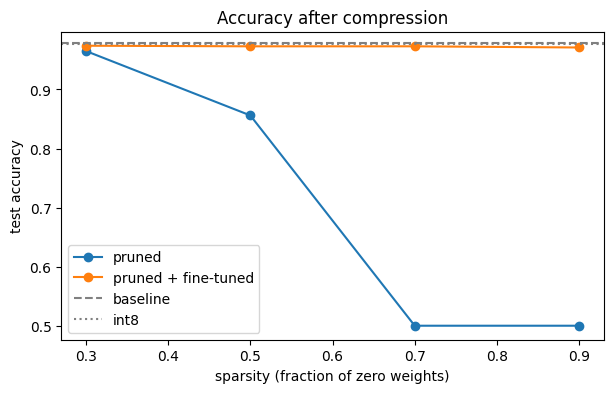

In [21]:
summary = pd.DataFrame(results)
baseline = summary.iloc[0]
summary["accuracy change (pp)"] = 100 * (summary["accuracy"] - baseline["accuracy"])
summary["size reduction (x)"] = baseline["size (MB)"] / summary["size (MB)"]
summary["speed-up (x)"] = baseline["CPU latency (ms)"] / summary["CPU latency (ms)"]
display(summary.round(3))

pruned_only = summary[summary["variant"].str.fullmatch(r"pruned \d+%")]
fine_tuned = summary[summary["variant"].str.endswith("fine-tuned")]
int8_rows = summary[summary["variant"] == "int8 quantized"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pruned_only["sparsity"], pruned_only["accuracy"], "o-", label="pruned")
if len(fine_tuned):
    ax.plot(fine_tuned["sparsity"], fine_tuned["accuracy"], "o-", label="pruned + fine-tuned")
ax.axhline(baseline["accuracy"], color="grey", linestyle="--", label="baseline")
if len(int8_rows):
    ax.axhline(int8_rows["accuracy"].iloc[0], color="grey", linestyle=":", label="int8")
ax.set(xlabel="sparsity (fraction of zero weights)", ylabel="test accuracy", title="Accuracy after compression")
ax.legend()
plt.show()

summary.to_csv(OUTPUT_DIR / "compression.csv", index=False)

### 7.4 Questions and ideas

- Which compression gives the best trade-off for your dataset? Where does the accuracy collapse?
- Why does pruning change neither the size nor the latency, while quantization changes both?
- Does fine-tuning recover the accuracy? Up to which sparsity is it enough?
- Combine the two: quantize a pruned model. MANOLO's workflow in section 8 does exactly that, and also measures the energy each step consumes.

In [22]:
calibration_results = []
for num_batches in (1, CALIBRATION_BATCHES):
    if num_batches == CALIBRATION_BATCHES:
        calibrated = int8_model
    else:
        calibrated = lu.quantizable_copy(model)
        calibration_loader.generator.manual_seed(SEED)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", DeprecationWarning)
            calibrated.fuse_model(is_qat=False)
            calibrated.qconfig = tq.get_default_qconfig(QUANT_ENGINE)
            tq.prepare(calibrated, inplace=True)
            lu.calibrate(calibrated, calibration_loader, num_batches)
            tq.convert(calibrated, inplace=True)
    metrics = lu.evaluate(calibrated, loaders["val"], torch.device("cpu"))
    calibration_results.append({
        "calibration batches": num_batches,
        "calibration images": min(num_batches * BATCH_SIZE, len(calibration_set)),
        "validation accuracy": metrics["accuracy"],
        "validation loss": metrics["loss"],
    })
    del calibrated
calibration_summary = pd.DataFrame(calibration_results)
display(calibration_summary.round(4))
calibration_summary.to_csv(OUTPUT_DIR / "calibration.csv", index=False)

/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  super().__init__(


,calibration batches,calibration images,validation accuracy,validation loss
0,1,64,0.9489,0.1945
1,10,640,0.9511,0.1938


### Task 3 answers

**3.1** Int8 quantization gives the best measured trade-off: test accuracy changes from **97.8% to 97.7%**, a loss of only **0.1 percentage points**, while model size falls from **44.76 MB to 11.30 MB** (**3.96x smaller**). CPU latency for the fixed batch of 32 images decreases from **575.38 ms to 378.31 ms**, a **1.52x speed-up**. Without fine-tuning, pruning accuracy drops from 96.5% at 30% sparsity to 85.6% at 50%, then collapses to 50.0% at both 70% and 90% sparsity, equal to the always-one-class baseline on this balanced test set.

**3.2** Unstructured pruning leaves the tensor shapes unchanged and stores the zero weights in dense tensors. Consequently, all pruned models remain approximately 44.76 MB and show no measured CPU speed-up. Their timings vary from about 579 to 855 ms; the timing differences do not demonstrate reduced computation from sparsity. Int8 quantization reduces the storage precision and uses integer kernels, producing both a smaller model and lower latency in this run. These latency measurements apply to this CPU and batch size.

**3.3** Two fine-tuning epochs recover most of the accuracy lost to pruning:

| Pruned weights | Before fine-tuning | After fine-tuning | Change from baseline after fine-tuning |
|---|---:|---:|---:|
| 30% | 96.5% | 97.4% | -0.4 percentage points |
| 50% | 85.6% | 97.3% | -0.5 percentage points |
| 70% | 50.0% | 97.3% | -0.5 percentage points |
| 90% | 50.0% | 97.1% | -0.7 percentage points |

Recovery remains substantial even at 90% sparsity, although none of the fine-tuned pruned models reaches the 97.8% baseline accuracy. Since this dense implementation gives no size or latency benefit from pruning, int8 remains the more useful compression option among those tested.

**3.4** Calibration with one batch (64 training images) gives **94.89% validation accuracy** and **0.1945 validation loss**. Ten batches (640 images) give **95.11% accuracy** and **0.1938 loss**. The additional batches improve accuracy by only **0.22 percentage points**, equivalent to four validation images. One batch is already close to the ten-batch result; ten batches perform slightly better in this comparison and were used for the reported int8 model. These two settings do not establish the minimum calibration budget or whether more than ten batches would help.

## 8. MANOLO

### 8.1 Dataset registration

### 8.2 Model registration

### 8.3 Workflow submission